# Examen Parcial - Informe 03 - Redes Neuronales Aprendizaje Profundo - Grupo 07
---
**Crisanto Palacios, Eduardo**
**Riveros Ruiz, Jason Wilmer**
**Torres Vela, Juan Carlos (Representante)**
**Zavala Suyo, Rafael**

---
**Prof. Dr.    Aldo Camargo**

---

# 04 · Posprocesamiento de monitoreo ecológico (sistema basado en reglas)

Convierte las detecciones por fotograma del detector YOLO en un **reporte de actividad por cámara y por especie**, como lo usaría un equipo de manejo de fauna:

| Salida | Contenido |
|---|---|
| Resumen por cámara | nº de imágenes, **tasa de vacías vs. con fauna**, nº de detecciones, **especies distintas**, eventos independientes, días-cámara |
| Cámara × especie | detecciones, imágenes, eventos independientes, confianza, índice de abundancia relativa (RAI) |
| Alertas | reglas operativas (cámara con exceso de vacías, especie rara, baja confianza, vehículo/humano, cámara silenciosa) |
| Validación | el mismo reporte calculado con la **verdad terreno** y comparado con el del modelo |

**Reglas (todas parametrizables en el diccionario `RULES`):**
1. *Umbral por especie* calibrado en **`cis_val`** (nunca en las cámaras de despliegue).
2. *Confirmación por secuencia:* una especie se confirma si aparece en ≥ 2 fotogramas de la misma ráfaga **o** con confianza alta en uno.
3. *Evento independiente:* detecciones de la misma especie en la misma cámara separadas < 30 min se cuentan como un solo evento (convención en ecología de cámaras trampa).
4. *Fauna vs. no-fauna:* la clase `car` no cuenta como fauna (genera alerta aparte).

Se aplica sobre **`trans_val`** (cámaras nunca vistas) para simular un despliegue real.

In [ ]:
!pip -q install -U ultralytics

In [ ]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

os.environ.setdefault('CCT_DRIVE_DIR', '/content/drive/MyDrive/Dfoto')
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
sys.path.insert(0, os.environ['CCT_DRIVE_DIR'])
import cct_utils as U
U.init(); U.load_classes()
meta = U.load_meta()

Mounted at /content/drive


## 1. Entradas
Se usan las detecciones guardadas por los notebooks 02/03 (`cct_yolo/preds/<RUN>_<split>.csv`). Si no existen, se calculan (requiere imágenes y GPU).

In [ ]:
RUN = 'baseline'          # o 'bgswap' si el notebook 03 lo mejoró
SPLIT_REPORT = 'trans_val'
SPLIT_CALIB = 'cis_val'

def get_preds(split):
    p = U.DRIVE_DIR / 'preds' / f'{RUN}_{split}.csv'
    if p.exists():
        return pd.read_csv(p)
    U.ensure_dataset()
    return U.predict_split(U.DRIVE_DIR / 'runs' / RUN / 'weights' / 'best.pt', split, RUN, conf=0.05)

P_cal, P_rep = get_preds(SPLIT_CALIB), get_preds(SPLIT_REPORT)
M_cal, M_rep = meta[meta.split == SPLIT_CALIB], meta[meta.split == SPLIT_REPORT]
print(f'{SPLIT_REPORT}: {len(M_rep):,} imágenes, {M_rep.location.nunique()} cámaras, {len(P_rep):,} detecciones (conf ≥ 0.05)')
has_time = M_rep['datetime'].notna().mean() > 0.5
print('¿Hay fechas utilizables?', has_time)

trans_val: 9,895 imágenes, 10 cámaras, 14,511 detecciones (conf ≥ 0.05)
¿Hay fechas utilizables? True


## 2. Calibración de umbrales por especie (solo con `cis_val`)
Para cada especie se elige el umbral que maximiza el F1 de *presencia en imagen*. Con pocos positivos (< `min_pos`) se usa el umbral global.

In [ ]:
def calibrate_thresholds(M, P, grid=np.arange(0.10, 0.91, 0.05), min_pos=10, default=0.35):
    out = {}
    files_all = set(M['file'])
    for c in U.CLASSES:
        gt = set(M.loc[M['species'].str.split('|').apply(lambda s: c in s), 'file'])
        if len(gt) < min_pos:
            continue
        mx = P[P['cls'] == c].groupby('file')['conf'].max()
        best_f1, best_t = -1, default
        for t in grid:
            pred = set(mx[mx >= t].index) & files_all
            tp = len(pred & gt); fp = len(pred - gt); fn = len(gt - pred)
            f1 = 2 * tp / max(2 * tp + fp + fn, 1)
            if f1 > best_f1:
                best_f1, best_t = f1, float(t)
        out[c] = round(best_t, 2)
    return out

thr_cls = calibrate_thresholds(M_cal, P_cal)
RULES = dict(
    conf_default=0.35,          # umbral para especies sin calibración
    conf_per_class=thr_cls,     # calibrado en cis_val
    conf_high=0.60,             # una sola foto con esta confianza basta para confirmar
    min_frames=2,               # o ≥ min_frames fotogramas de la misma secuencia
    non_fauna=['car'],          # clases que no cuentan como fauna
    independence_min=30,        # minutos para fusionar eventos de la misma especie y cámara
    empty_rate_alert=0.85,      # alerta de cámara con exceso de vacías
    rare_event_max=2,           # especie "rara" = ≤ N eventos en todo el despliegue
    low_conf_alert=0.50,        # evento cuya confianza máxima queda por debajo de este valor
    silent_days=14,             # días sin imágenes para marcar cámara silenciosa
)
print('Umbrales calibrados:', thr_cls)
(U.DRIVE_DIR / 'summaries').mkdir(exist_ok=True)
json.dump(RULES, open(U.DRIVE_DIR / 'summaries' / 'reglas_monitoreo.json', 'w'), indent=2)

Umbrales calibrados: {'bird': 0.45, 'bobcat': 0.45, 'car': 0.65, 'cat': 0.65, 'coyote': 0.25, 'deer': 0.1, 'dog': 0.55, 'opossum': 0.45, 'rabbit': 0.45, 'raccoon': 0.6, 'rodent': 0.3, 'skunk': 0.1, 'squirrel': 0.3}


## 3. Motor de reglas
`build_report(M, P, rules)` recibe los metadatos de las imágenes (cámara, secuencia, fecha) y las detecciones, y devuelve cuatro tablas: **cámaras**, **cámara × especie**, **eventos** y **alertas**.

In [ ]:
def build_report(M, P, rules):
    non_fauna = set(rules['non_fauna'])
    M = M.copy()
    M['location'] = M['location'].astype(str)

    # 1) umbral por especie
    thr = P['cls'].map(lambda c: rules['conf_per_class'].get(c, rules['conf_default']))
    D = P[P['conf'] >= thr].merge(M[['file', 'location', 'seq_key', 'datetime']], on='file', how='inner')

    # 2) confirmación por secuencia y especie
    g = (D.groupby(['location', 'seq_key', 'cls'])
           .agg(n_frames=('file', 'nunique'), max_conf=('conf', 'max'), t=('datetime', 'min')).reset_index())
    g['confirmed'] = (g['max_conf'] >= rules['conf_high']) | (g['n_frames'] >= rules['min_frames'])
    conf_keys = g[g['confirmed']][['location', 'seq_key', 'cls']]
    Dc = D.merge(conf_keys, on=['location', 'seq_key', 'cls'], how='inner')
    ev_seq = g[g['confirmed']].copy()

    # 3) eventos independientes (misma cámara y especie, hueco < independence_min)
    ev_seq = ev_seq.sort_values(['location', 'cls', 't'])
    gap = ev_seq.groupby(['location', 'cls'])['t'].diff() > pd.Timedelta(minutes=rules['independence_min'])
    first_in_group = ev_seq.groupby(['location', 'cls']).cumcount() == 0
    new_event = gap | ev_seq['t'].isna() | first_in_group
    ev_seq['event_id'] = new_event.cumsum()
    events = (ev_seq.groupby('event_id')
                .agg(location=('location', 'first'), cls=('cls', 'first'), inicio=('t', 'min'),
                     n_secuencias=('seq_key', 'nunique'), n_fotogramas=('n_frames', 'sum'),
                     conf_max=('max_conf', 'max')).reset_index(drop=True))

    # 4) imágenes con fauna / vehículo según detecciones confirmadas
    fauna_files = set(Dc[~Dc['cls'].isin(non_fauna)]['file'])
    veh_files = set(Dc[Dc['cls'].isin(non_fauna)]['file'])

    # --- tabla por cámara
    cam = M.groupby('location').agg(n_imagenes=('file', 'size'), primera=('datetime', 'min'), ultima=('datetime', 'max'))
    cam['n_con_fauna'] = M[M['file'].isin(fauna_files)].groupby('location').size().reindex(cam.index).fillna(0).astype(int)
    cam['n_vacias'] = cam['n_imagenes'] - cam['n_con_fauna']
    cam['tasa_vacias'] = cam['n_vacias'] / cam['n_imagenes']
    cam['tasa_con_fauna'] = 1 - cam['tasa_vacias']
    Df = Dc[~Dc['cls'].isin(non_fauna)]
    cam['n_detecciones'] = Df.groupby('location').size().reindex(cam.index).fillna(0).astype(int)
    ev_f = events[~events['cls'].isin(non_fauna)]
    cam['n_eventos'] = ev_f.groupby('location').size().reindex(cam.index).fillna(0).astype(int)
    cam['n_especies'] = ev_f.groupby('location')['cls'].nunique().reindex(cam.index).fillna(0).astype(int)
    cam['especies'] = ev_f.groupby('location')['cls'].apply(lambda s: ', '.join(sorted(set(s)))).reindex(cam.index).fillna('')
    cam['n_img_vehiculo'] = M[M['file'].isin(veh_files)].groupby('location').size().reindex(cam.index).fillna(0).astype(int)
    cam['dias_camara'] = ((cam['ultima'] - cam['primera']).dt.days + 1).where(cam['primera'].notna())
    cam['eventos_por_100_dias'] = 100 * cam['n_eventos'] / cam['dias_camara']

    # --- tabla cámara × especie
    cs = (Dc.groupby(['location', 'cls'])
            .agg(n_detecciones=('conf', 'size'), n_imagenes=('file', 'nunique'), conf_media=('conf', 'mean'), conf_max=('conf', 'max'))
            .reset_index())
    ev_cnt = events.groupby(['location', 'cls']).size().rename('n_eventos').reset_index()
    cs = cs.merge(ev_cnt, on=['location', 'cls'], how='left').fillna({'n_eventos': 0})
    cs['n_eventos'] = cs['n_eventos'].astype(int)
    cs = cs.merge(cam[['dias_camara']].reset_index(), on='location', how='left')
    cs['RAI_100dias'] = 100 * cs['n_eventos'] / cs['dias_camara']     # aprox. de eventos por 100 noches-trampa
    cs['es_fauna'] = ~cs['cls'].isin(non_fauna)

    # --- alertas
    alerts = []
    for loc, r in cam.iterrows():
        if r['tasa_vacias'] > rules['empty_rate_alert']:
            alerts.append((loc, 'EXCESO_VACIAS', '', f"{r['tasa_vacias']:.0%} de fotos sin fauna: revisar sensibilidad/vegetación frente al sensor"))
        if r['n_img_vehiculo'] > 0:
            alerts.append((loc, 'VEHICULO_O_HUMANO', 'car', f"{int(r['n_img_vehiculo'])} imágenes con vehículo: posible presencia humana"))
        if pd.notna(r['dias_camara']) and pd.notna(r['primera']):
            tt = M[M['location'] == loc]['datetime'].dropna().sort_values()
            if len(tt) > 1:
                gmax = tt.diff().max()
                if gmax > pd.Timedelta(days=rules['silent_days']):
                    alerts.append((loc, 'CAMARA_SILENCIOSA', '', f'hueco de {gmax.days} días sin imágenes: posible falla o batería'))
    tot_ev = events[~events['cls'].isin(non_fauna)].groupby('cls').size()
    for sp, n in tot_ev.items():
        if n <= rules['rare_event_max']:
            where = ', '.join(sorted(events[events['cls'] == sp]['location'].unique()))
            alerts.append((where, 'ESPECIE_RARA', sp, f'solo {n} evento(s) en todo el despliegue: verificar manualmente'))
    for r in events[(events['conf_max'] < rules['low_conf_alert']) & ~events['cls'].isin(non_fauna)].itertuples():
        alerts.append((r.location, 'BAJA_CONFIANZA', r.cls, f'confianza máx. {r.conf_max:.2f}: verificar manualmente'))
    alerts = pd.DataFrame(alerts, columns=['camara', 'regla', 'especie', 'detalle'])
    return cam, cs, events, alerts

cam, cs, events, alerts = build_report(M_rep, P_rep, RULES)
display_cols = ['n_imagenes', 'n_con_fauna', 'tasa_vacias', 'n_detecciones', 'n_eventos', 'n_especies', 'especies', 'dias_camara', 'eventos_por_100_dias']
print('RESUMEN POR CÁMARA (modelo)')
cam[display_cols].round(2)

RESUMEN POR CÁMARA (modelo)


,n_imagenes,n_con_fauna,tasa_vacias,n_detecciones,n_eventos,n_especies,especies,dias_camara,eventos_por_100_dias
location,,,,,,,,,
0,1000,324,0.68,339,306,11,"badger, bird, bobcat, cat, coyote, deer, dog, ...",703,43.53
100,1002,884,0.12,935,296,10,"bird, bobcat, cat, coyote, dog, opossum, rabbi...",376,78.72
105,1000,707,0.29,739,250,9,"bird, bobcat, cat, coyote, dog, opossum, rabbi...",409,61.12
125,1001,709,0.29,766,325,11,"bird, bobcat, cat, coyote, deer, dog, opossum,...",391,83.12
130,1000,743,0.26,803,218,11,"bird, bobcat, cat, coyote, dog, opossum, rabbi...",367,59.40
28,1000,673,0.33,693,319,10,"bird, bobcat, cat, coyote, dog, opossum, rabbi...",426,74.88
40,890,656,0.26,687,167,11,"bird, bobcat, cat, coyote, dog, fox, opossum, ...",409,40.83
46,1000,688,0.31,749,295,11,"bird, bobcat, cat, coyote, deer, dog, opossum,...",402,73.38
7,1001,868,0.13,952,257,11,"bird, bobcat, cat, coyote, deer, dog, opossum,...",377,68.17


In [ ]:
print('CÁMARA × ESPECIE (modelo)')
cs.sort_values(['location', 'n_eventos'], ascending=[True, False]).round(2).head(30)

CÁMARA × ESPECIE (modelo)


,location,cls,n_detecciones,n_imagenes,conf_media,conf_max,n_eventos,dias_camara,RAI_100dias,es_fauna
3,0,car,675,674,0.97,0.99,497,703,70.70,False
5,0,coyote,148,143,0.85,0.92,134,703,19.06,True
2,0,bobcat,71,71,0.86,0.94,69,703,9.82,True
7,0,dog,74,69,0.80,0.92,60,703,8.53,True
10,0,skunk,26,25,0.81,0.90,24,703,3.41,True
8,0,fox,5,5,0.73,0.80,5,703,0.71,True
11,0,squirrel,6,5,0.60,0.72,5,703,0.71,True
1,0,bird,3,3,0.68,0.74,3,703,0.43,True
4,0,cat,2,2,0.79,0.85,2,703,0.28,True
6,0,deer,2,2,0.84,0.90,2,703,0.28,True


In [ ]:
print(f'ALERTAS ({len(alerts)}):')
alerts.groupby('regla').size().rename('n').to_frame()

ALERTAS (67):


,n
regla,
BAJA_CONFIANZA,57
CAMARA_SILENCIOSA,6
ESPECIE_RARA,2
VEHICULO_O_HUMANO,2


In [ ]:
alerts.head(25)

,camara,regla,especie,detalle
0,0,VEHICULO_O_HUMANO,car,674 imágenes con vehículo: posible presencia h...
1,0,CAMARA_SILENCIOSA,,hueco de 105 días sin imágenes: posible falla ...
2,105,CAMARA_SILENCIOSA,,hueco de 133 días sin imágenes: posible falla ...
3,125,CAMARA_SILENCIOSA,,hueco de 15 días sin imágenes: posible falla o...
4,40,CAMARA_SILENCIOSA,,hueco de 41 días sin imágenes: posible falla o...
5,46,VEHICULO_O_HUMANO,car,33 imágenes con vehículo: posible presencia hu...
6,46,CAMARA_SILENCIOSA,,hueco de 33 días sin imágenes: posible falla o...
7,7,CAMARA_SILENCIOSA,,hueco de 22 días sin imágenes: posible falla o...
8,0,ESPECIE_RARA,badger,solo 1 evento(s) en todo el despliegue: verifi...
9,130,ESPECIE_RARA,rodent,solo 1 evento(s) en todo el despliegue: verifi...


## 4. Validación del módulo: reporte del modelo vs. reporte de la verdad terreno
Se aplica **el mismo motor** a "detecciones" construidas con las anotaciones reales (confianza 1). Las diferencias miden cuánto distorsionan los errores del detector las métricas ecológicas.

In [ ]:
gt_rows = []
for r in M_rep.itertuples():
    for sp in [s for s in r.species.split('|') if s]:
        gt_rows.append((r.file, sp, 1.0, 0, 0, 1, 1))
P_gt = pd.DataFrame(gt_rows, columns=['file', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2'])
RULES_GT = dict(RULES, conf_per_class={}, conf_default=0.0, conf_high=0.0, min_frames=1)
cam_gt, cs_gt, ev_gt, _ = build_report(M_rep, P_gt, RULES_GT)

cmp_cam = cam[['n_imagenes', 'tasa_vacias', 'n_eventos', 'n_especies']].join(
    cam_gt[['tasa_vacias', 'n_eventos', 'n_especies']], rsuffix='_real', how='outer')
cmp_cam['err_tasa_vacias'] = (cmp_cam['tasa_vacias'] - cmp_cam['tasa_vacias_real']).abs()
cmp_cam['err_riqueza'] = cmp_cam['n_especies'] - cmp_cam['n_especies_real']
print('Comparación por cámara (modelo vs real)')
print(cmp_cam.round(2).to_string())

mm = cs[cs.es_fauna].merge(cs_gt[cs_gt.es_fauna], on=['location', 'cls'], how='outer', suffixes=('_pred', '_real'))
mm[['n_eventos_pred', 'n_eventos_real']] = mm[['n_eventos_pred', 'n_eventos_real']].fillna(0)
mae = (mm['n_eventos_pred'] - mm['n_eventos_real']).abs().mean()
rho = mm[['n_eventos_pred', 'n_eventos_real']].corr(method='spearman').iloc[0, 1]
pred_pres, real_pres = mm['n_eventos_pred'] > 0, mm['n_eventos_real'] > 0
prec = (pred_pres & real_pres).sum() / max(pred_pres.sum(), 1)
rec = (pred_pres & real_pres).sum() / max(real_pres.sum(), 1)
print(f'\nEventos por cámara×especie → MAE = {mae:.2f} · Spearman = {rho:.2f}')
print(f'Presencia de especie por cámara → precisión = {prec:.2f} · recall = {rec:.2f}')
print(f'Error absoluto medio de la tasa de vacías por cámara = {cmp_cam["err_tasa_vacias"].mean():.3f}')
print(f'Error medio de riqueza de especies por cámara = {cmp_cam["err_riqueza"].mean():+.2f} (positivo = el modelo sobrestima)')

Comparación por cámara (modelo vs real)
          n_imagenes  tasa_vacias  n_eventos  n_especies  tasa_vacias_real  n_eventos_real  n_especies_real  err_tasa_vacias  err_riqueza
location                                                                                                                                 
0               1000         0.68        306          11              0.63             336                9             0.04            2
100             1002         0.12        296          10              0.05             288                9             0.07            1
105             1000         0.29        250           9              0.05             232                7             0.25            2
125             1001         0.29        325          11              0.04             303                8             0.25            3
130             1000         0.26        218          11              0.09             198               10             0.16        

## 5. Visualizaciones del reporte

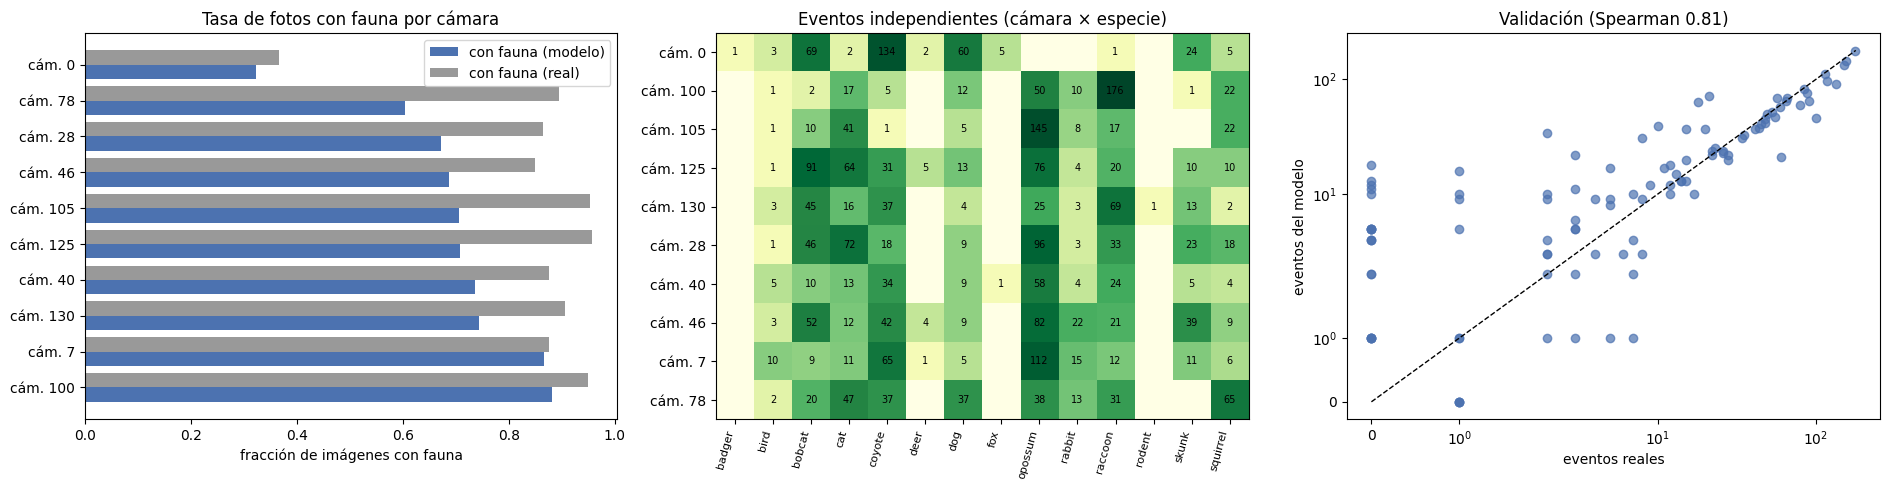

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))
order = cam.sort_values('tasa_vacias').index
y = np.arange(len(order))
ax[0].barh(y - 0.2, 1 - cam.loc[order, 'tasa_vacias'], 0.4, label='con fauna (modelo)', color='#4C72B0')
ax[0].barh(y + 0.2, 1 - cam_gt.reindex(order)['tasa_vacias'], 0.4, label='con fauna (real)', color='#999999')
ax[0].set_yticks(y); ax[0].set_yticklabels([f'cám. {c}' for c in order]); ax[0].set_xlabel('fracción de imágenes con fauna')
ax[0].set_title('Tasa de fotos con fauna por cámara'); ax[0].legend()

H = cs[cs.es_fauna].pivot_table(index='location', columns='cls', values='n_eventos', fill_value=0)
im = ax[1].imshow(np.log1p(H.values), aspect='auto', cmap='YlGn')
ax[1].set_xticks(range(H.shape[1])); ax[1].set_xticklabels(H.columns, rotation=75, ha='right', fontsize=8)
ax[1].set_yticks(range(H.shape[0])); ax[1].set_yticklabels([f'cám. {c}' for c in H.index])
for i in range(H.shape[0]):
    for j in range(H.shape[1]):
        if H.values[i, j] > 0:
            ax[1].text(j, i, int(H.values[i, j]), ha='center', va='center', fontsize=7)
ax[1].set_title('Eventos independientes (cámara × especie)')

lim = max(mm['n_eventos_pred'].max(), mm['n_eventos_real'].max()) + 1
ax[2].scatter(mm['n_eventos_real'], mm['n_eventos_pred'], alpha=0.7, color='#4C72B0')
ax[2].plot([0, lim], [0, lim], 'k--', lw=1); ax[2].set_xscale('symlog'); ax[2].set_yscale('symlog')
ax[2].set_xlabel('eventos reales'); ax[2].set_ylabel('eventos del modelo'); ax[2].set_title(f'Validación (Spearman {rho:.2f})')
plt.tight_layout(); plt.show()

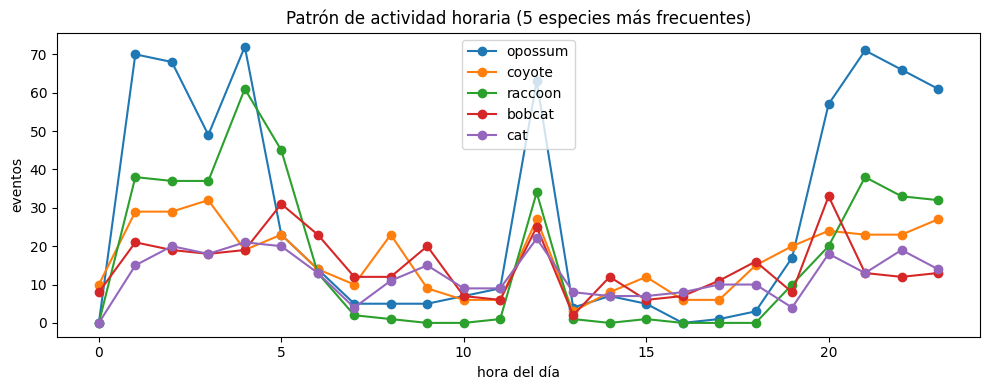

In [ ]:
if has_time:
    ev = events[~events['cls'].isin(RULES['non_fauna'])].dropna(subset=['inicio']).copy()
    ev['hora'] = ev['inicio'].dt.hour
    top = ev['cls'].value_counts().head(5).index
    fig, ax = plt.subplots(figsize=(10, 4))
    for sp in top:
        h = ev[ev['cls'] == sp]['hora'].value_counts().reindex(range(24), fill_value=0)
        ax.plot(h.index, h.values, marker='o', label=sp)
    ax.set_xlabel('hora del día'); ax.set_ylabel('eventos'); ax.set_title('Patrón de actividad horaria (5 especies más frecuentes)'); ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('Sin fechas utilizables: se omite el patrón de actividad horaria.')

## 6. Reporte narrativo y exportación
Se escribe un resumen en texto por cámara y se exportan CSV + un Excel con todas las hojas (`cct_yolo/reportes/`).

In [ ]:
def narrativa(cam, cs):
    lines = []
    for loc, r in cam.iterrows():
        sp = cs[(cs.location == loc) & cs.es_fauna].sort_values('n_eventos', ascending=False)
        top = ', '.join(f"{x.cls} ({x.n_eventos})" for x in sp.head(3).itertuples()) or 'sin fauna confirmada'
        lines.append(f"Cámara {loc}: {int(r['n_imagenes'])} fotos, {r['tasa_vacias']:.0%} vacías; "
                     f"{int(r['n_especies'])} especie(s) distintas y {int(r['n_eventos'])} evento(s) independientes. Más frecuentes: {top}.")
    return '\n'.join(lines)

txt = narrativa(cam, cs)
print(txt)

out_dir = U.DRIVE_DIR / 'reportes'; out_dir.mkdir(exist_ok=True)
cam.reset_index().to_csv(out_dir / f'{RUN}_{SPLIT_REPORT}_resumen_camaras.csv', index=False)
cs.to_csv(out_dir / f'{RUN}_{SPLIT_REPORT}_camara_especie.csv', index=False)
events.to_csv(out_dir / f'{RUN}_{SPLIT_REPORT}_eventos.csv', index=False)
alerts.to_csv(out_dir / f'{RUN}_{SPLIT_REPORT}_alertas.csv', index=False)
(out_dir / f'{RUN}_{SPLIT_REPORT}_resumen.txt').write_text(txt)
with pd.ExcelWriter(out_dir / f'{RUN}_{SPLIT_REPORT}_reporte_monitoreo.xlsx', engine='openpyxl') as xw:
    cam.reset_index().to_excel(xw, sheet_name='resumen_camaras', index=False)
    cs.to_excel(xw, sheet_name='camara_especie', index=False)
    events.to_excel(xw, sheet_name='eventos', index=False)
    alerts.to_excel(xw, sheet_name='alertas', index=False)
    cmp_cam.reset_index().to_excel(xw, sheet_name='validacion_vs_real', index=False)
    pd.DataFrame({'regla': list(RULES.keys()), 'valor': [json.dumps(v) for v in RULES.values()]}).to_excel(
        xw, sheet_name='reglas', index=False)
print('\nReportes guardados en', out_dir)

Cámara 0: 1000 fotos, 68% vacías; 11 especie(s) distintas y 306 evento(s) independientes. Más frecuentes: coyote (134), bobcat (69), dog (60).
Cámara 100: 1002 fotos, 12% vacías; 10 especie(s) distintas y 296 evento(s) independientes. Más frecuentes: raccoon (176), opossum (50), squirrel (22).
Cámara 105: 1000 fotos, 29% vacías; 9 especie(s) distintas y 250 evento(s) independientes. Más frecuentes: opossum (145), cat (41), squirrel (22).
Cámara 125: 1001 fotos, 29% vacías; 11 especie(s) distintas y 325 evento(s) independientes. Más frecuentes: bobcat (91), opossum (76), cat (64).
Cámara 130: 1000 fotos, 26% vacías; 11 especie(s) distintas y 218 evento(s) independientes. Más frecuentes: raccoon (69), bobcat (45), coyote (37).
Cámara 28: 1000 fotos, 33% vacías; 10 especie(s) distintas y 319 evento(s) independientes. Más frecuentes: opossum (96), cat (72), bobcat (46).
Cámara 40: 890 fotos, 26% vacías; 11 especie(s) distintas y 167 evento(s) independientes. Más frecuentes: opossum (58), c

## 7. Limitaciones y notas para el informe
- **Días-cámara** se aproxima por el rango de fechas de las imágenes muestreadas (no hay metadatos de esfuerzo de muestreo); como el dataset se submuestrea, `RAI_100dias` es un índice relativo, no una abundancia absoluta.
- La mezcla vacía/fauna de la partición depende del muestreo (solo se usan imágenes con bbox o marcadas `empty`), por lo que la tasa de vacías no reproduce exactamente el ~70 % del dataset completo.
- Los umbrales por especie con pocos positivos en `cis_val` son inestables: se usa el umbral global.
- Las alertas son reglas heurísticas; en operación deberían calibrarse con el equipo de manejo (p. ej. qué tasa de vacías es "normal" para cada sitio).
- Mejora posible: un filtro previo con MegaDetector para descartar vacías antes de clasificar la especie.

## 8. Entregable 5 · Módulo de monitoreo con demostración sobre una cámara NO vista en entrenamiento

El módulo (secciones 2–3: umbrales por especie, confirmación por secuencia, eventos independientes, alertas) se empaqueta ahora en una función única:

`monitor_sequence(frames, weights, rules)` → recibe los **fotogramas de una cámara** (archivo, fecha, secuencia), **ejecuta el detector sobre cada fotograma**, aplica las reglas y devuelve:
1. resumen de la cámara y alertas,
2. **actividad por especie y por periodo** (calendario: día / semana / mes según la duración del registro),
3. **actividad por especie y franja horaria** (madrugada / mañana / tarde / noche),
4. lista de eventos independientes.

Demostración: se elige automáticamente una cámara de `trans_val` (ubicación que **no** participó en el entrenamiento) con registro temporal amplio, se procesa **toda su secuencia cronológica** y el reporte se compara con el que resulta de la verdad terreno.

> Notas: las fechas son las de la cámara (se asume hora local). El dataset se submuestrea por secuencias, por lo que la actividad es un **índice relativo de esfuerzo muestreado**, no una abundancia absoluta.

In [ ]:
from ultralytics import YOLO
from PIL import Image, ImageDraw

def predict_frames(model, split, files, conf=0.05, batch=64):
    """Ejecuta el detector sobre una lista de fotogramas; devuelve una fila por detección (coordenadas normalizadas)."""
    rows = []
    for i in range(0, len(files), batch):
        chunk = files[i:i + batch]
        res = model.predict([str(U.LOCAL / 'images' / split / f) for f in chunk], conf=conf, iou=0.6, imgsz=U.IMGSZ, verbose=False)
        for f, r in zip(chunk, res):
            b = r.boxes
            if b is None or len(b) == 0:
                continue
            xy, c, s = b.xyxyn.cpu().numpy(), b.cls.cpu().numpy().astype(int), b.conf.cpu().numpy()
            for k in range(len(c)):
                rows.append((f, U.CLASSES[c[k]], float(s[k]), *[float(v) for v in xy[k]]))
    return pd.DataFrame(rows, columns=['file', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2'])

def franja_horaria(h):
    return pd.cut(h, bins=[-1, 5, 11, 17, 23], labels=['madrugada (00-05)', 'mañana (06-11)', 'tarde (12-17)', 'noche (18-23)'])

def auto_freq(M):
    t = M['datetime'].dropna()
    span = (t.max() - t.min()).days if len(t) else 0
    return 'D' if span <= 14 else ('W' if span <= 120 else 'M')

def activity_tables(events, M, rules, freq=None):
    """Actividad por especie × periodo y por especie × franja horaria, a partir de los eventos independientes."""
    freq = freq or auto_freq(M)
    ev = events[~events['cls'].isin(rules['non_fauna'])].dropna(subset=['inicio']).copy()
    ev['periodo'] = ev['inicio'].dt.to_period(freq).astype(str)
    ev['franja'] = franja_horaria(ev['inicio'].dt.hour)
    Mt = M.dropna(subset=['datetime']).copy()
    Mt['periodo'] = Mt['datetime'].dt.to_period(freq).astype(str)
    esfuerzo = Mt.groupby('periodo').agg(imagenes=('file', 'size'), dias_muestreados=('datetime', lambda s: s.dt.normalize().nunique()))
    largo = (ev.groupby(['cls', 'periodo']).agg(eventos=('inicio', 'size'), secuencias=('n_secuencias', 'sum'),
                                                fotogramas=('n_fotogramas', 'sum'), conf_media=('conf_max', 'mean'))
               .reset_index().merge(esfuerzo, left_on='periodo', right_index=True, how='left'))
    largo['eventos_por_dia_muestreado'] = largo['eventos'] / largo['dias_muestreados'].replace(0, np.nan)
    ancho = largo.pivot(index='cls', columns='periodo', values='eventos').fillna(0).astype(int)
    ancho['TOTAL'] = ancho.sum(axis=1); ancho = ancho.sort_values('TOTAL', ascending=False)
    franja = (ev.groupby(['cls', 'franja'], observed=False).size().unstack('franja', fill_value=0)
                .reindex(columns=franja_horaria(pd.Series([0, 6, 12, 18])).cat.categories, fill_value=0))
    franja['TOTAL'] = franja.sum(axis=1); franja = franja.sort_values('TOTAL', ascending=False)
    return dict(freq=freq, largo=largo, ancho=ancho, franja=franja, esfuerzo=esfuerzo, eventos=ev)

def monitor_sequence(frames, weights, rules, split='trans_val', conf=0.05, freq=None):
    """MÓDULO DE MONITOREO: fotogramas de una cámara -> detecciones -> reglas -> reportes tabulares.
    `frames`: DataFrame con file, location, seq_key, datetime (ordenado o no)."""
    frames = frames.sort_values('datetime').reset_index(drop=True)
    P = predict_frames(YOLO(str(weights)), split, frames['file'].tolist(), conf=conf)
    cam_, cs_, ev_, al_ = build_report(frames, P, rules)
    act = activity_tables(ev_, frames, rules, freq)
    return dict(frames=frames, preds=P, camara=cam_, camara_especie=cs_, alertas=al_, **act)

In [ ]:
U.ensure_dataset()
DEMO_CAMERA = None          # p. ej. '33'; None = elegir automáticamente
W_BEST = U.DRIVE_DIR / 'runs' / RUN / 'weights' / 'best.pt'

cand = (M_rep.dropna(subset=['datetime']).groupby('location')
        .agg(imagenes=('file', 'size'), secuencias=('seq_key', 'nunique'), dias_span=('datetime', lambda s: (s.max() - s.min()).days)))
cand = cand[cand.imagenes >= 100].sort_values(['dias_span', 'imagenes'], ascending=False)
print('Cámaras candidatas (trans_val, nunca vistas en entrenamiento):'); print(cand.to_string())
DEMO_CAMERA = str(DEMO_CAMERA or cand.index[0])
assert DEMO_CAMERA in set(M_rep.location.astype(str)), 'La cámara elegida no pertenece a trans_val'
frames = M_rep[M_rep.location.astype(str) == DEMO_CAMERA].dropna(subset=['datetime'])
assert DEMO_CAMERA not in set(meta[meta.split == 'train'].location.astype(str)), 'La cámara aparece en entrenamiento'
print(f'\n>>> Cámara de demostración: {DEMO_CAMERA} | {len(frames):,} fotogramas | {frames.seq_key.nunique()} secuencias | '
      f"{frames.datetime.min():%Y-%m-%d} → {frames.datetime.max():%Y-%m-%d}")

DEMO = monitor_sequence(frames, W_BEST, RULES)
print(f"Detecciones brutas (conf ≥ 0.05): {len(DEMO['preds']):,} | periodo del reporte: {DEMO['freq']} "
      f"({ {'D': 'día', 'W': 'semana', 'M': 'mes'}[DEMO['freq']] })")

print('\n=== REPORTE 1 · Resumen de la cámara ===')
print(DEMO['camara'][['n_imagenes', 'n_con_fauna', 'tasa_vacias', 'n_eventos', 'n_especies', 'especies', 'dias_camara']].round(2).to_string())
print('\n=== REPORTE 2 · Actividad por ESPECIE y PERIODO (nº de eventos independientes) ===')
print(DEMO['ancho'].to_string())
print('\n=== REPORTE 3 · Actividad por ESPECIE y FRANJA HORARIA ===')
print(DEMO['franja'].to_string())
print('\n=== REPORTE 4 · Detalle largo (esfuerzo de muestreo y confianza por especie × periodo) ===')
print(DEMO['largo'].round(2).sort_values(['periodo', 'eventos'], ascending=[True, False]).head(25).to_string(index=False))
print(f"\n=== ALERTAS ({len(DEMO['alertas'])}) ==="); print(DEMO['alertas'].head(15).to_string(index=False))

out_dir = U.DRIVE_DIR / 'reportes'; out_dir.mkdir(exist_ok=True)
tag = f'demo_camara{DEMO_CAMERA}_{RUN}'
DEMO['ancho'].reset_index().to_csv(out_dir / f'{tag}_actividad_especie_periodo.csv', index=False)
DEMO['franja'].reset_index().to_csv(out_dir / f'{tag}_actividad_especie_franja.csv', index=False)
DEMO['largo'].to_csv(out_dir / f'{tag}_actividad_detalle.csv', index=False)
DEMO['eventos'].to_csv(out_dir / f'{tag}_eventos.csv', index=False)
with pd.ExcelWriter(out_dir / f'{tag}.xlsx', engine='openpyxl') as xw:
    DEMO['camara'].reset_index().to_excel(xw, sheet_name='resumen_camara', index=False)
    DEMO['ancho'].reset_index().to_excel(xw, sheet_name='especie_x_periodo', index=False)
    DEMO['franja'].reset_index().to_excel(xw, sheet_name='especie_x_franja', index=False)
    DEMO['largo'].to_excel(xw, sheet_name='detalle', index=False)
    DEMO['eventos'].to_excel(xw, sheet_name='eventos', index=False)
    DEMO['alertas'].to_excel(xw, sheet_name='alertas', index=False)
print('\nReportes guardados en', out_dir, f'(prefijo {tag})')

Cámaras candidatas (trans_val, nunca vistas en entrenamiento):
          imagenes  secuencias  dias_span
location                                 
0             1000        1000        702
28            1000         430        425
105           1000         377        408
40             890         308        408
78            1001         401        403
46            1000         400        401
125           1001         387        390
7             1001         385        376
100           1002         356        375
130           1000         381        366

>>> Cámara de demostración: 0 | 1,000 fotogramas | 1000 secuencias | 2011-05-05 → 2013-04-07
Detecciones brutas (conf ≥ 0.05): 1,378 | periodo del reporte: M (mes)

=== REPORTE 1 · Resumen de la cámara ===
          n_imagenes  n_con_fauna  tasa_vacias  n_eventos  n_especies                                                                     especies  dias_camara
location                                                          

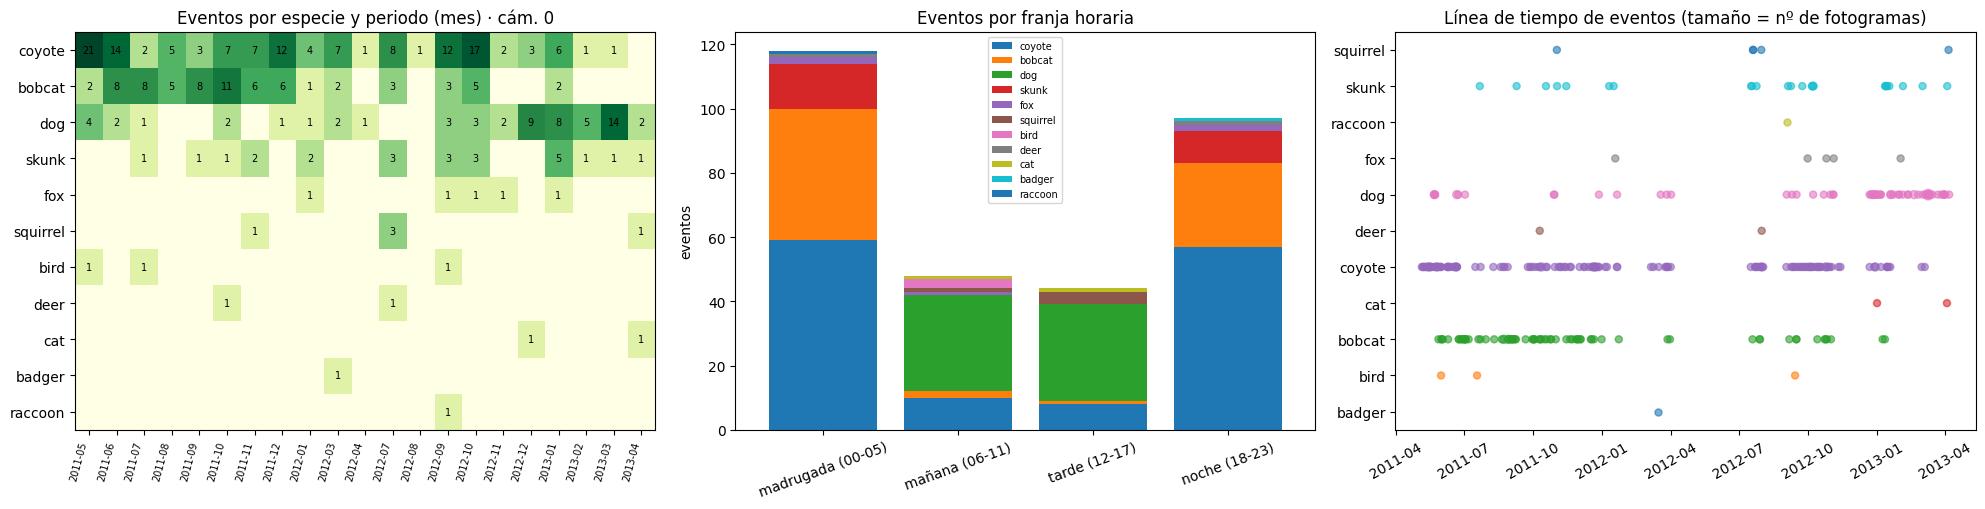

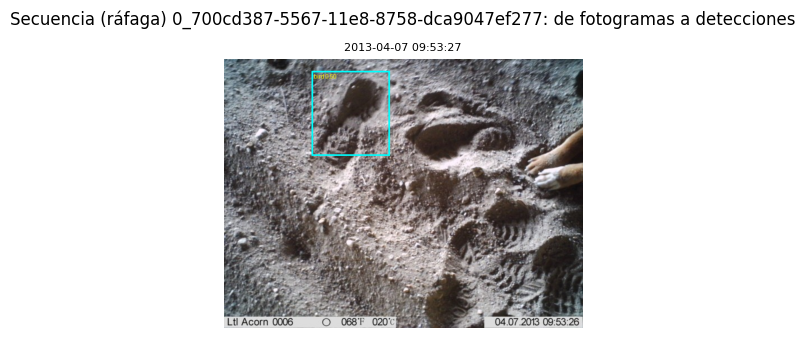

In [ ]:
(U.DRIVE_DIR / 'figs').mkdir(exist_ok=True)
ev_d = DEMO['eventos']; ancho_d = DEMO['ancho'].drop(columns='TOTAL'); fr_d = DEMO['franja'].drop(columns='TOTAL')
fig, ax = plt.subplots(1, 3, figsize=(20, 5.2))
if len(ancho_d):
    im = ax[0].imshow(np.log1p(ancho_d.values), aspect='auto', cmap='YlGn')
    ax[0].set_xticks(range(ancho_d.shape[1])); ax[0].set_xticklabels(ancho_d.columns, rotation=75, ha='right', fontsize=7)
    ax[0].set_yticks(range(ancho_d.shape[0])); ax[0].set_yticklabels(ancho_d.index)
    for i in range(ancho_d.shape[0]):
        for j in range(ancho_d.shape[1]):
            if ancho_d.values[i, j]:
                ax[0].text(j, i, int(ancho_d.values[i, j]), ha='center', va='center', fontsize=7)
ax[0].set_title(f'Eventos por especie y periodo ({ {"D": "día", "W": "semana", "M": "mes"}[DEMO["freq"]] }) · cám. {DEMO_CAMERA}')
if len(fr_d):
    fr_d.T.plot.bar(stacked=True, ax=ax[1], width=.8, legend=True); ax[1].tick_params(axis='x', rotation=20)
ax[1].set_title('Eventos por franja horaria'); ax[1].set_ylabel('eventos'); ax[1].legend(fontsize=7)
for k, sp in enumerate(sorted(ev_d['cls'].unique())):
    e = ev_d[ev_d['cls'] == sp]
    ax[2].scatter(e['inicio'], [k] * len(e), s=18 + 8 * e['n_fotogramas'], alpha=.6, label=sp)
ax[2].set_yticks(range(ev_d['cls'].nunique())); ax[2].set_yticklabels(sorted(ev_d['cls'].unique()))
ax[2].set_title('Línea de tiempo de eventos (tamaño = nº de fotogramas)'); ax[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(U.DRIVE_DIR / 'figs' / f'demo_camara{DEMO_CAMERA}_actividad.png', dpi=150); plt.show()

# Ráfaga de ejemplo: la secuencia con más fotogramas con detección confirmada
thr_f = lambda c: RULES['conf_per_class'].get(c, RULES['conf_default'])
Pd_ = DEMO['preds']; Pd_ = Pd_[Pd_.apply(lambda r: r.conf >= thr_f(r.cls), axis=1)]
fs = DEMO['frames'].merge(Pd_.groupby('file').size().rename('n_det'), left_on='file', right_index=True)
if len(fs):
    seq = fs.groupby('seq_key').n_det.size().sort_values(ascending=False).index[0]
    burst = DEMO['frames'][DEMO['frames'].seq_key == seq].sort_values('datetime').head(6)
    fig, axs = plt.subplots(1, len(burst), figsize=(4.2 * len(burst), 3.4), squeeze=False)
    for a_, r in zip(axs[0], burst.itertuples()):
        im = Image.open(U.LOCAL / 'images' / 'trans_val' / r.file).convert('RGB'); W, H = im.size; d = ImageDraw.Draw(im)
        for q in Pd_[Pd_.file == r.file].itertuples():
            d.rectangle([q.x1 * W, q.y1 * H, q.x2 * W, q.y2 * H], outline='cyan', width=3); d.text((q.x1 * W + 3, q.y1 * H + 3), f'{q.cls} {q.conf:.2f}', fill='yellow')
        a_.imshow(im); a_.axis('off'); a_.set_title(f'{r.datetime:%Y-%m-%d %H:%M:%S}', fontsize=8)
    plt.suptitle(f'Secuencia (ráfaga) {seq}: de fotogramas a detecciones'); plt.tight_layout(); plt.show()

In [ ]:
# ¿Cuánto se parece el reporte del modelo al de la verdad terreno en esta cámara?
gt_rows = [(r.file, sp, 1.0, 0, 0, 1, 1) for r in DEMO['frames'].itertuples() for sp in r.species.split('|') if sp]
P_gt_d = pd.DataFrame(gt_rows, columns=['file', 'cls', 'conf', 'x1', 'y1', 'x2', 'y2'])
R_gt = dict(RULES, conf_per_class={}, conf_default=0.0, conf_high=0.0, min_frames=1)
_, _, ev_gt, _ = build_report(DEMO['frames'], P_gt_d, R_gt)
act_gt = activity_tables(ev_gt, DEMO['frames'], R_gt, DEMO['freq'])

def tot(a): return a['ancho']['TOTAL'] if len(a['ancho']) else pd.Series(dtype=int)
cmp_ev = pd.concat([tot(DEMO).rename('eventos_modelo'), tot(act_gt).rename('eventos_reales')], axis=1).fillna(0).astype(int)
cmp_ev['error'] = cmp_ev['eventos_modelo'] - cmp_ev['eventos_reales']
print('EVENTOS POR ESPECIE · modelo vs. verdad terreno (cámara no vista)')
print(cmp_ev.sort_values('eventos_reales', ascending=False).to_string())
per_m, per_r = DEMO['ancho'].drop(columns='TOTAL', errors='ignore'), act_gt['ancho'].drop(columns='TOTAL', errors='ignore')
cols = sorted(set(per_m.columns) | set(per_r.columns)); idx = sorted(set(per_m.index) | set(per_r.index))
A, B = per_m.reindex(index=idx, columns=cols, fill_value=0), per_r.reindex(index=idx, columns=cols, fill_value=0)
from scipy.stats import spearmanr
if A.size > 3 and B.values.std() > 0 and A.values.std() > 0:
    rho_, _ = spearmanr(A.values.ravel(), B.values.ravel())
    print(f'\nConcordancia por celda especie × periodo: Spearman = {rho_:.2f} | MAE = {np.abs(A.values - B.values).mean():.2f} eventos/celda')
pres = ((A > 0) & (B > 0)).values.sum() / max((B > 0).values.sum(), 1)
print(f'Celdas especie × periodo con actividad real que el modelo también reporta: {pres:.0%}  (el complemento son ausencias falsas)')
cmp_ev.reset_index().to_csv(U.DRIVE_DIR / 'reportes' / f'{tag}_validacion_vs_real.csv', index=False)

EVENTOS POR ESPECIE · modelo vs. verdad terreno (cámara no vista)
          eventos_modelo  eventos_reales  error
cls                                            
coyote               134             150    -16
dog                   60              79    -19
bobcat                70              66      4
skunk                 24              26     -2
bird                   3               6     -3
squirrel               5               3      2
badger                 1               3     -2
raccoon                1               2     -1
rabbit                 0               1     -1
fox                    5               0      5
deer                   2               0      2
cat                    2               0      2

Concordancia por celda especie × periodo: Spearman = 0.89 | MAE = 0.27 eventos/celda
Celdas especie × periodo con actividad real que el modelo también reporta: 93%  (el complemento son ausencias falsas)


## 9. Entregable 6 · Costo de los falsos negativos (cuantificación para la discusión)

Un falso negativo en un conteo de imágenes es un error; en un programa de manejo es una **ausencia falsa** (una especie que está, pero el reporte dice que no). Esta sección cuantifica ese riesgo con los datos del proyecto en tres pasos:

1. **Ausencias falsas por especie:** pares cámara × especie con presencia real que el sistema no reporta (cámaras nuevas).
2. **Costo asimétrico:** el umbral por especie se elige en `cis_val` minimizando `λ · FN + FP` (λ = cuántas veces es peor perder una especie que revisar una falsa alarma) y se evalúa en `trans_val`.
3. **Qué cuesta ser cauteloso:** falsas alarmas adicionales que un revisor humano tendría que descartar por cada falso negativo evitado.

> CCT-20 no trae categorías de amenaza (UICN). Por defecto se tratan como «prioritarias» las especies con menos ejemplos de entrenamiento presentes en la prueba; sustituye `PRIORITY` por tu lista de especies amenazadas.

In [ ]:
PRIORITY = None                 # p. ej. ['badger', 'fox']; None = las 3 especies con menos instancias de train presentes en la prueba
LAMBDAS = [1, 10, 50]
inst_train_ = U.count_instances('train')
present = {c for s in M_rep.species for c in s.split('|') if c} - set(RULES['non_fauna'])
PRIORITY = PRIORITY or sorted(present, key=lambda c: inst_train_.get(c, 0))[:3]
print('Especies prioritarias:', {c: f'{inst_train_.get(c, 0)} inst. train' for c in PRIORITY})

def counts(M, P, c, t):
    gt = set(M.loc[M['species'].str.split('|').apply(lambda s: c in s), 'file'])
    mx = P[P['cls'] == c].groupby('file')['conf'].max()
    pred = set(mx[mx >= t].index) & set(M['file'])
    return len(gt), len(gt & pred), len(pred - gt), len(gt - pred)       # n_real, TP, FP, FN

def best_thr_cost(M, P, c, lam, grid=np.arange(0.05, 0.91, 0.05)):
    cost = [(lam * counts(M, P, c, t)[3] + counts(M, P, c, t)[2], t) for t in grid]    # empate -> umbral más bajo
    return float(min(cost)[1])

rows = []
for c in PRIORITY:
    t0 = RULES['conf_per_class'].get(c, RULES['conf_default'])
    n, tp0, fp0, fn0 = counts(M_rep, P_rep, c, t0)
    rows.append(dict(especie=c, inst_train=inst_train_.get(c, 0), criterio='F1 actual (sección 2)', umbral=t0, imgs_reales=n,
                     FN=fn0, recall=tp0 / max(n, 1), FP=fp0, FP_extra_por_FN_evitado=np.nan))
    for lam in LAMBDAS:
        t = best_thr_cost(M_cal, P_cal, c, lam)           # se elige SOLO con cis_val
        n, tp, fp, fn = counts(M_rep, P_rep, c, t)
        rows.append(dict(especie=c, inst_train=inst_train_.get(c, 0), criterio=f'costo λ={lam}', umbral=t, imgs_reales=n, FN=fn,
                         recall=tp / max(n, 1), FP=fp, FP_extra_por_FN_evitado=(fp - fp0) / (fn0 - fn) if fn0 > fn else np.nan))
FNT = pd.DataFrame(rows)
print('\nCOSTO ASIMÉTRICO (umbral elegido en cis_val, resultados en trans_val, nivel imagen)')
print(FNT.round(3).to_string(index=False))

if 'mm' in globals():
    pairs = mm[mm.cls.isin(PRIORITY)].copy()
    pairs['ausencia_falsa'] = (pairs.n_eventos_real > 0) & (pairs.n_eventos_pred == 0)
    pairs['presencia_real'] = pairs.n_eventos_real > 0
    af = pairs.groupby('cls').agg(pares_camara_especie_reales=('presencia_real', 'sum'), ausencias_falsas=('ausencia_falsa', 'sum'))
    af['tasa_ausencia_falsa'] = af.ausencias_falsas / af.pares_camara_especie_reales.replace(0, np.nan)
    print('\nAUSENCIAS FALSAS a nivel de gestión (cámara × especie con presencia real que el reporte omite)')
    print(af.round(3).to_string())
    allp = mm.assign(real=mm.n_eventos_real > 0, miss=(mm.n_eventos_real > 0) & (mm.n_eventos_pred == 0))
    print(f'Referencia, todas las especies fauna: {int(allp.miss.sum())} de {int(allp.real.sum())} presencias reales omitidas ({allp.miss.sum() / max(allp.real.sum(), 1):.0%}).')
FNT.to_csv(U.DRIVE_DIR / 'summaries' / 'entregable6_costo_falsos_negativos.csv', index=False)
print('\nLectura: al subir λ el umbral baja, el recall sube y aparecen más falsas alarmas; "FP_extra_por_FN_evitado" es el precio en revisión humana de cada especie recuperada.')

Especies prioritarias: {'badger': '5 inst. train', 'skunk': '259 inst. train', 'rodent': '264 inst. train'}

COSTO ASIMÉTRICO (umbral elegido en cis_val, resultados en trans_val, nivel imagen)
especie  inst_train              criterio  umbral  imgs_reales  FN  recall  FP  FP_extra_por_FN_evitado
 badger           5 F1 actual (sección 2)    0.35            8   7   0.125   2                      NaN
 badger           5             costo λ=1    0.05            8   5   0.375   6                      2.0
 badger           5            costo λ=10    0.05            8   5   0.375   6                      2.0
 badger           5            costo λ=50    0.05            8   5   0.375   6                      2.0
  skunk         259 F1 actual (sección 2)    0.10          196  18   0.908 192                      NaN
  skunk         259             costo λ=1    0.10          196  18   0.908 192                      NaN
  skunk         259            costo λ=10    0.10          196  18   0.908 192 

## 10. Entregable 6 · Discusión: uso responsable de la IA en conservación (≈ media página)

**El falso negativo es el error caro.** En conservación, los dos errores del detector no pesan lo mismo. Una falsa alarma cuesta minutos de un revisor; un **falso negativo** sobre una especie amenazada es silencioso: nadie revisa lo que el sistema declara «vacío», el dato falta en el registro y, aguas abajo, se vuelve una **ausencia falsa** que alimenta modelos de ocupación y abundancia y decisiones como prioridades de manejo, financiamiento o incluso la valoración de si una población persiste. El daño es acumulativo (una especie rara con pocas detecciones es la primera que se descarta como «no presente») y potencialmente irreversible, porque la intervención llega tarde o nunca.

**Por qué ocurre.** Los entregables 2 a 4 miden los factores que agravan este riesgo: las especies con pocos ejemplos de entrenamiento tienden a tener menor AP y recall (entregable 2), el rendimiento puede caer en cámaras nuevas, que es donde se despliega el sistema (entregable 3), y baja con animales pequeños u ocluidos (entregable 4). La métrica global (mAP) esconde este sesgo porque la dominan las especies comunes. *(Completar con las cifras obtenidas en cada tabla.)*

**Prácticas propuestas.**
1. Evaluar y reportar **por especie y por cámara nueva**, con intervalos de confianza, nunca solo el promedio.
2. Fijar el umbral con una **función de costo asimétrica** (λ > 1) para las especies prioritarias, aceptando más falsas alarmas a cambio de recall (sección 9), con **revisión humana** de las detecciones de baja confianza y de las especies raras (reglas `ESPECIE_RARA` y `BAJA_CONFIANZA`).
3. **No interpretar «sin detección» como «ausencia»**: usar modelos de ocupación que corrijan la probabilidad de detección y auditar periódicamente una muestra aleatoria de las imágenes que el sistema descartó como vacías.
4. Recalibrar y revalidar ante cada cámara o hábitat nuevo, y documentar límites conocidos (una semilla, pocas cámaras, proxy de oclusión).
5. **Gobernanza de datos:** las ubicaciones exactas de especies amenazadas son sensibles (riesgo de caza furtiva); restringir su difusión.

## 11. Consolidado de entregables (2 a 6) en un solo Excel

Reúne las tablas de los notebooks 02, 03 y 04 (`cct_yolo/summaries/` y `cct_yolo/reportes/`) en `cct_yolo/reportes/entregables_2_a_6.xlsx`. Las hojas que falten (por secciones no ejecutadas) se omiten.

In [ ]:
SUM = U.DRIVE_DIR / 'summaries'; REP = U.DRIVE_DIR / 'reportes'
SHEETS = {
    'E2_global': SUM / f'{RUN}_entregable2_global.csv',
    'E2_por_especie': SUM / f'{RUN}_entregable2_por_especie.csv',
    'E2_destino_instancias': SUM / f'{RUN}_entregable2_destino_instancias.csv',
    'E3_brecha_cis_trans': SUM / 'entregable3_brecha_cis_trans.csv',
    'E3_mAP_por_camara': SUM / 'exp_generalizacion_por_camara.csv',
    'E3_brecha_por_especie': SUM / 'entregable3_brecha_por_especie.csv',
    'E3_gradcam_resumen': SUM / 'entregable3_gradcam_resumen.csv',
    'E3_fantasmas': SUM / 'entregable3_fantasmas.csv',
    'E3_intercambio_fondo': SUM / 'entregable3_intercambio_fondo.csv',
    'E3_sintesis': SUM / 'entregable3_sintesis.csv',
    'E4_desempeno_grupo': SUM / 'entregable4_desempeno_por_grupo.csv',
    'E4_caida_grupos': SUM / 'entregable4_caida_entre_grupos.csv',
    'E4_oclusion_controlada': SUM / 'entregable4_oclusion_controlada.csv',
    'E4_sintesis': SUM / 'entregable4_sintesis.csv',
    'E6_costo_FN': SUM / 'entregable6_costo_falsos_negativos.csv',
}
for key, pat in [('E5_demo_periodo', 'demo_camara*_actividad_especie_periodo.csv'), ('E5_demo_franja', 'demo_camara*_actividad_especie_franja.csv'),
                 ('E5_demo_detalle', 'demo_camara*_actividad_detalle.csv'), ('E5_demo_vs_real', 'demo_camara*_validacion_vs_real.csv')]:
    hits = sorted(REP.glob(pat))
    if hits:
        SHEETS[key] = hits[-1]
written, missing = [], []
with pd.ExcelWriter(REP / 'entregables_2_a_6.xlsx', engine='openpyxl') as xw:
    for sheet, p in SHEETS.items():
        if p.exists():
            pd.read_csv(p).to_excel(xw, sheet_name=sheet[:31], index=False); written.append(sheet)
        else:
            missing.append(p.name)
print('Hojas escritas:', written)
if missing:
    print('No encontradas (ejecuta las secciones correspondientes):', missing)
figs = sorted((U.DRIVE_DIR / 'figs').glob('*.png')) if (U.DRIVE_DIR / 'figs').exists() else []
print('Figuras para el informe:', [f.name for f in figs])
print('Excel:', REP / 'entregables_2_a_6.xlsx')

Hojas escritas: ['E2_global', 'E2_por_especie', 'E3_brecha_cis_trans', 'E3_mAP_por_camara', 'E3_brecha_por_especie', 'E3_gradcam_resumen', 'E3_fantasmas', 'E3_intercambio_fondo', 'E3_sintesis', 'E4_desempeno_grupo', 'E4_caida_grupos', 'E4_oclusion_controlada', 'E4_sintesis', 'E6_costo_FN', 'E5_demo_periodo', 'E5_demo_franja', 'E5_demo_detalle', 'E5_demo_vs_real']
No encontradas (ejecuta las secciones correspondientes): ['baseline_entregable2_destino_instancias.csv']
Figuras para el informe: ['baseline_entregable2_ap_vs_desbalance.png', 'demo_camara0_actividad.png', 'entregable4_oclusion_controlada.png', 'entregable4_tamano_oclusion.png', 'gradcam_baseline.png', 'gradcam_bgswap.png']
Excel: /content/drive/MyDrive/Dfoto/reportes/entregables_2_a_6.xlsx
